## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Emma Chung

**Date:** 10/12/2026

Q1.1

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([np.random.normal(1, noise, N),
                   np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N),
                   np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N),
                   np.random.normal(3, noise, N)])

    gdf1 = pd.DataFrame({'x1': X1[0,:], 'x2': X1[1,:], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0,:], 'x2': X2[1,:], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0,:], 'x2': X3[1,:], 'group': 'c'})

    return pd.concat([gdf1, gdf2, gdf3], axis=0)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}


Q1.2

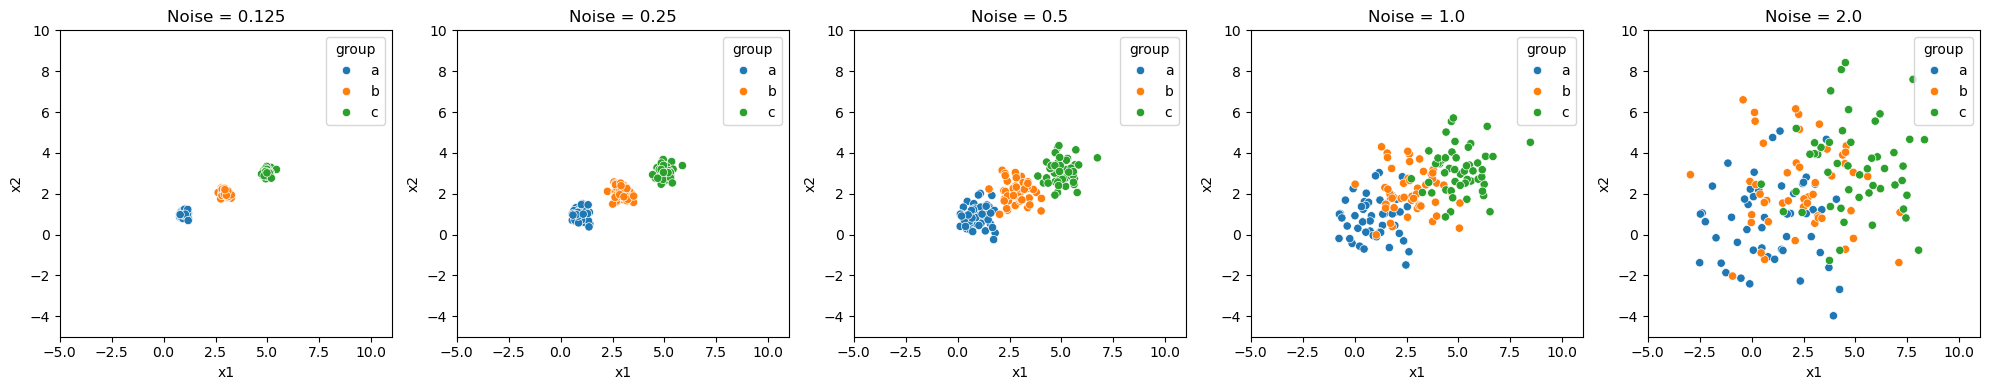

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, (noise, df) in zip(axes, datasets.items()):
    sns.scatterplot(
        data=df,
        x='x1',
        y='x2',
        hue='group',
        ax=ax
    )
    ax.set_title(f'Noise = {noise}')
    ax.set_xlim(-5, 11)
    ax.set_ylim(-5, 10)

plt.tight_layout()
plt.show()

As the noise increases, the clusters become less visually distinct. At lower noise levels (0.125 and 0.25), the three groups are tightly concentrated around their centers and are easy to distinguish. At 0.5, the clusters begin to spread out but are still mostly separate. At higher noise levels (1.0 and 2.0), the points overlap significantly, making it much harder to identify the original groups visually.

Q1.3

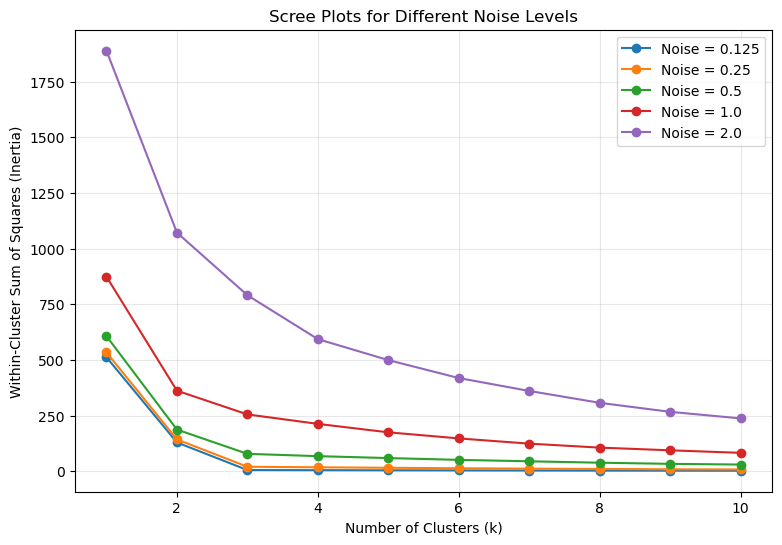

In [4]:
plt.figure(figsize=(9, 6))

for noise, df in datasets.items():
    X = df[['x1', 'x2']]
    inertia = []

    for k in range(1, 11):
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        model.fit(X)
        inertia.append(model.inertia_)

    plt.plot(range(1, 11), inertia, marker='o',
             label=f'Noise = {noise}')

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (Inertia)')
plt.title('Scree Plots for Different Noise Levels')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

At lower noise levels, the scree plots show a clearer elbow around k = 3, which matches the three groups used to generate the data. As noise increases, the curves become smoother and the elbow becomes less obvious. This makes it harder to confidently choose the correct number of clusters. Higher noise levels also produce larger inertia values because the points are more spread out from their cluster centers.

Q1.4

The elbow method helps determine the number of clusters by looking at how much the within-cluster sum of squares decreases as k increases. Adding more clusters will always reduce inertia, but eventually the improvements become much smaller. The elbow is the point where this reduction begins to slow down.
In this simulation, k = 3 is a reasonable choice when noise is low because the data were generated from three distinct groups. Increasing k beyond 3 mostly divides existing groups into smaller clusters rather than identifying meaningful new ones. When noise is high, the groups overlap, so the elbow becomes less clear and choosing k becomes more subjective.

Q2.1

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

After filtering the data to 2020 and dropping missing values, I was left with 148 countries. The spending variables were already numeric, so no additional cleaning was needed. However, I still needed to normalize the variables before using k-means because they are measured on different scales.

In [13]:
military = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")

features1 = ["Spending (2020 USD)", "Spending per Capita"]
features2 = ["Percent of Government Spending", "Percent of GDP"]
features3 = features1 + features2

military_2020 = military[military["Year"] == 2020].copy()

for col in features3:
    military_2020[col] = pd.to_numeric(
        military_2020[col], errors="coerce"
    )

military_2020 = military_2020.dropna(subset=features3).copy()

print("Number of countries:", len(military_2020))
print("\nData types:")
print(military_2020[features3].dtypes)

military_2020.head()

Number of countries: 148

Data types:
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


After filtering the dataset to 2020 and removing rows with missing values, I was left with 148 countries. All four spending variables were already numeric, so I did not need to convert their data types. I used min-max normalization before clustering because the variables have different scales.

Q2.2

In [14]:
scaler1 = MinMaxScaler()
X1 = scaler1.fit_transform(military_2020[features1])

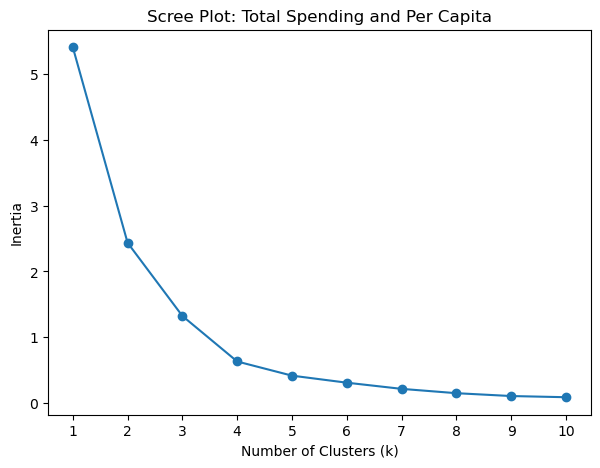

In [15]:
inertia1 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X1)
    inertia1.append(model.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertia1, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot: Total Spending and Per Capita")
plt.xticks(range(1, 11))
plt.show()

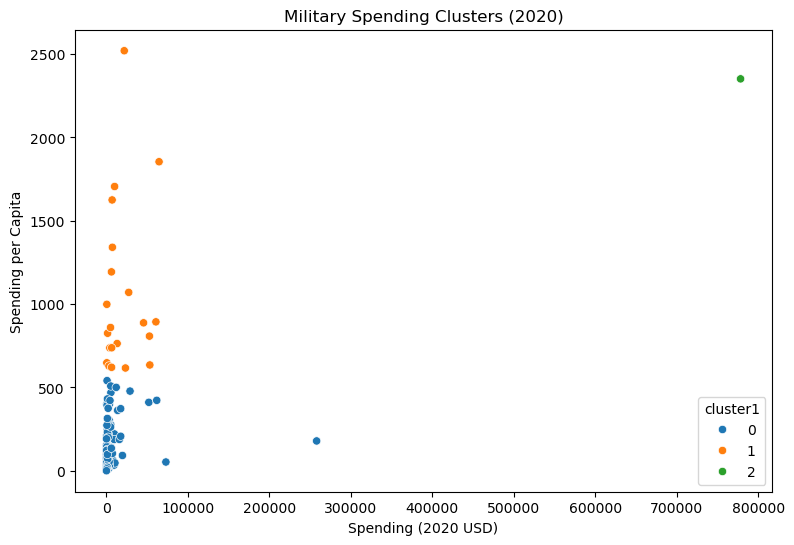

In [16]:
model1 = KMeans(n_clusters=3, random_state=42, n_init=10)

military_2020["cluster1"] = model1.fit_predict(X1)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=military_2020,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster1",
    palette="tab10"
)

plt.title("Military Spending Clusters (2020)")
plt.show()

In [17]:
display(military_2020.groupby("cluster1")[features1].describe())

print("Countries in each cluster:")
print(military_2020["cluster1"].value_counts().sort_index())

Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster1                                                                   
0                      126.0    5943.346303  24858.961064       8.622460   
1                       21.0   19975.991473  21749.736747     405.790494   
2                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster1                                                               
0            162.761743     580.758315    3225.333414  257973.429834   
1           4980.428135    7269.880030   27300.894701   64558.400000   
2         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita                                        \
                       count         mean         std          min   
cluster1                                                             
0                      126.0   122.034996  140.041183     0.580129   
1                       21.0  1046.433509  501.631845   616.854430   
2                        1.0  2351.631858         NaN  2351.631858   

                                                              
                  25%          50%          75%          max  
cluster1                                                      
0           18.505805    58.809109   188.249364   541.154778  
1          737.690186   859.880548  1193.598730  2520.398541  
2         2351.631858  2351.631858  2351.631858  2351.631858

Countries in each cluster:
cluster1
0    126
1     21
2      1
Name: count, dtype: int64


In [18]:
military_2020.loc[
    military_2020["Country"] == "United States of America",
    ["Country", "cluster1"] + features1
]

,Country,cluster1,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


I selected k = 3 based on the scree plot. The largest cluster contained 126 countries with relatively low total spending and spending per capita. Another cluster contained 21 countries with higher spending per capita. The United States formed its own cluster, with total military spending of approximately 778,397 in the dataset's units and spending per capita of $2,352.

This suggests that the United States is an outlier in terms of total military spending. It also shows that some countries can have relatively high spending per capita without having an extremely large total military budget.

Q2.3

In [19]:
scaler2 = MinMaxScaler()
X2 = scaler2.fit_transform(military_2020[features2])

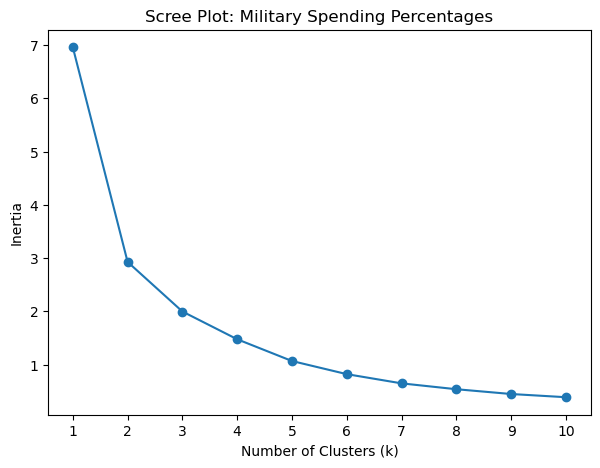

In [20]:
inertia2 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X2)
    inertia2.append(model.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertia2, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot: Military Spending Percentages")
plt.xticks(range(1, 11))
plt.show()

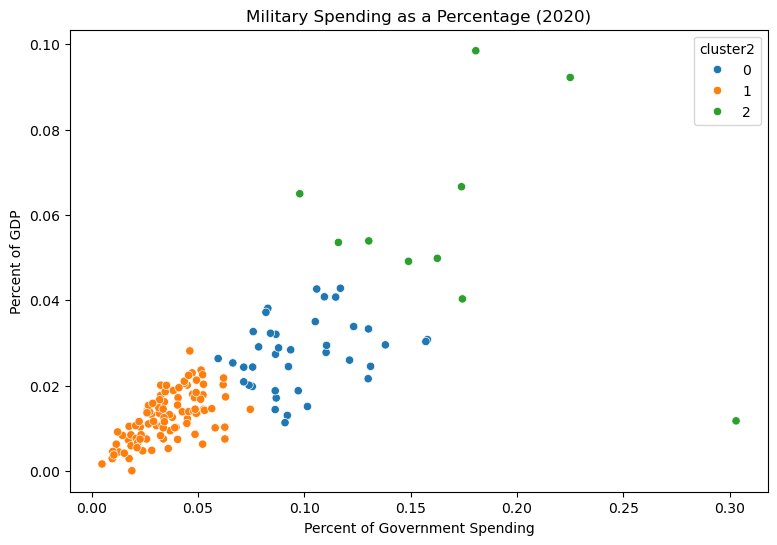

In [21]:
model2 = KMeans(n_clusters=3, random_state=42, n_init=10)

military_2020["cluster2"] = model2.fit_predict(X2)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=military_2020,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster2",
    palette="tab10"
)

plt.title("Military Spending as a Percentage (2020)")
plt.show()

In [22]:
display(military_2020.groupby("cluster2")[features2].describe())

print("Countries in each cluster:")
print(military_2020["cluster2"].value_counts().sort_index())

Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  99.0  0.035777  0.014549  0.004896   
2                                  10.0  0.171289  0.058725  0.097882   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                      
               std       min       25%       50%       75%       max  
cluster2                                                              
0         0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1         0.005681  0.000054  0.008393  0.013191  0.016752  0.028132  
2         0.024867  0.011742  0.049297  0.053729  0.066190  0.098470

Countries in each cluster:
cluster2
0    39
1    99
2    10
Name: count, dtype: int64


In [23]:
cluster2_means = military_2020.groupby("cluster2")[
    "Percent of GDP"
].mean()

highest_cluster2 = cluster2_means.idxmax()

military_2020.loc[
    military_2020["cluster2"] == highest_cluster2,
    ["Country"] + features2
].sort_values("Percent of GDP", ascending=False)

,Country,Percent of Government Spending,Percent of GDP
4044,Oman,0.180654,0.098470
4486,Saudi Arabia,0.225050,0.092211
100,Algeria,0.173924,0.066600
2922,Kuwait,0.097882,0.064961
304,Azerbaijan,0.130339,0.053905
2582,Israel,0.116052,0.053553
202,Armenia,0.162572,0.049827
2718,Jordan,0.149025,0.049121
4078,Pakistan,0.174362,0.040317
406,Belarus,0.303027,0.011742


I selected k = 3 for this analysis as well. Most countries (99) were grouped into a cluster with relatively low military spending as a percentage of GDP and government spending. Another 39 countries had moderate percentages, while 10 countries were in the highest-spending cluster, including Saudi Arabia, Oman, and Israel.

Unlike the previous analysis, these clusters reflect how much of a country's resources are allocated to the military rather than how much money is spent overall. A country can have a smaller military budget but still devote a large percentage of its GDP or government spending to the military.

Q2.4

In [24]:
scaler3 = MinMaxScaler()
X3 = scaler3.fit_transform(military_2020[features3])

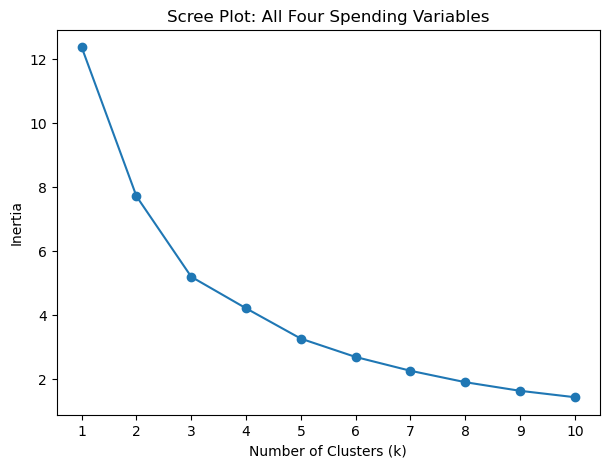

In [25]:
inertia3 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X3)
    inertia3.append(model.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertia3, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot: All Four Spending Variables")
plt.xticks(range(1, 11))
plt.show()

In [26]:
model3 = KMeans(n_clusters=3, random_state=42, n_init=10)

military_2020["cluster3"] = model3.fit_predict(X3)

print("Countries in each cluster:")
print(military_2020["cluster3"].value_counts().sort_index())

Countries in each cluster:
cluster3
0     31
1      6
2    111
Name: count, dtype: int64


In [27]:
display(military_2020.groupby("cluster3")[features3].describe())

Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster3                                                                  
0                       31.0    8786.086602   17901.909108   162.373364   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                      111.0    7086.472777   26479.379918     8.622460   

                                                                  \
                  25%           50%           75%            max   
cluster3                                                           
0          467.787851   1404.787234   7739.166193   72937.064048   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2          130.010211    567.650747   3910.107493  257973.429834   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...                            75%   
cluster3                                   ...                                  
0                       31.0   212.689100  ...                       0.134663   
1                        6.0  1875.150751  ...                       0.164503   
2                      111.0   196.926833  ...                       0.050505   

                   Percent of GDP                                          \
               max          count      mean       std       min       25%   
cluster3                                                                    
0         0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
1         0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2         0.092044          111.0  0.013419  0.005996  0.000054  0.008873   

                                        
               50%       75%       max  
cluster3                                
0         0.032024  0.040531  0.066600  
1         0.059257  0.085398  0.098470  
2         0.013589  0.017769  0.028132  

[3 rows x 32 columns]

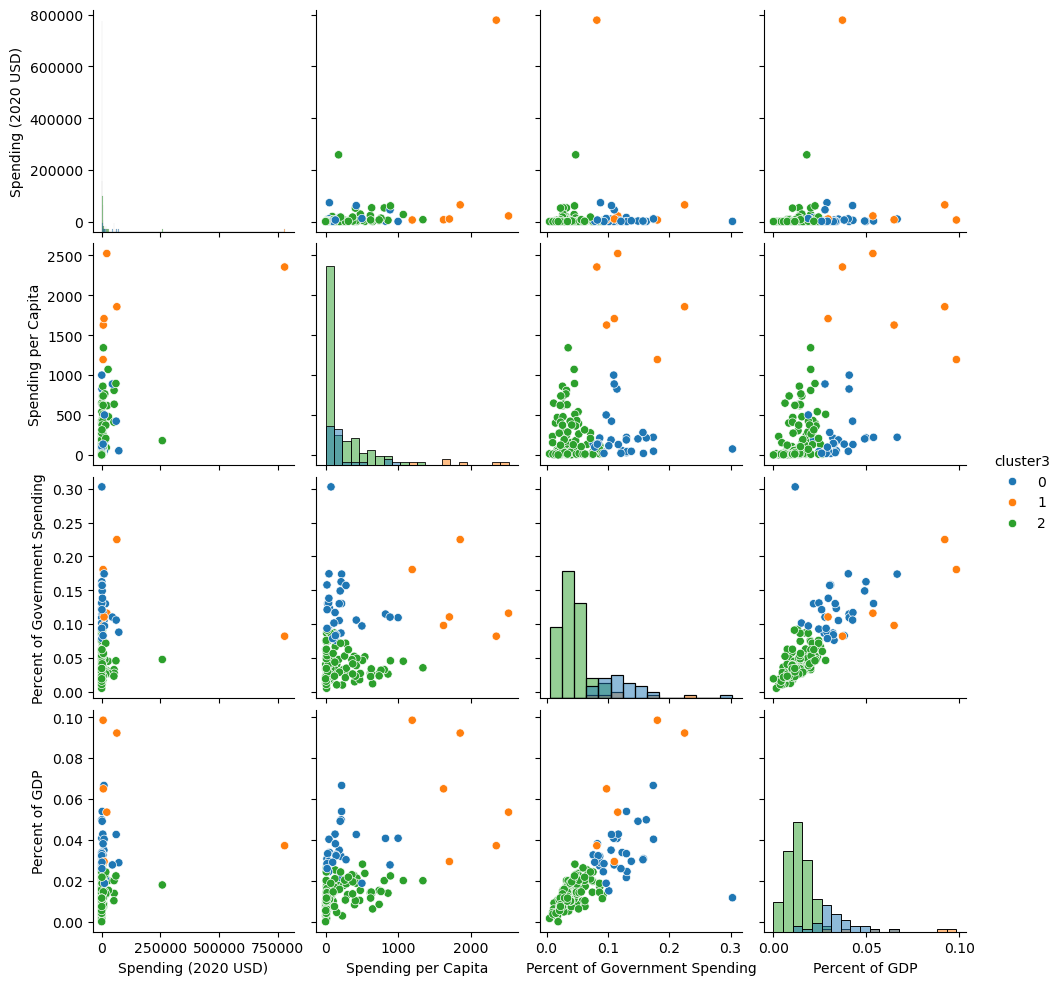

In [28]:
sns.pairplot(
    military_2020,
    vars=features3,
    hue="cluster3",
    palette="tab10",
    diag_kind="hist"
)

plt.show()

In [29]:
print("Comparison of Q2.2 and Q2.4:")
display(pd.crosstab(
    military_2020["cluster1"],
    military_2020["cluster3"]
))

print("Comparison of Q2.3 and Q2.4:")
display(pd.crosstab(
    military_2020["cluster2"],
    military_2020["cluster3"]
))

Comparison of Q2.2 and Q2.4:


cluster3,0,1,2
cluster1,,,
0,28,0,98
1,3,5,13
2,0,1,0


Comparison of Q2.3 and Q2.4:


cluster3,0,1,2
cluster2,,,
0,25,2,12
1,0,0,99
2,6,4,0


In [30]:
us_cluster3 = military_2020.loc[
    military_2020["Country"] == "United States of America",
    "cluster3"
].iloc[0]

print("Countries in the same cluster as the United States:")

display(military_2020.loc[
    military_2020["cluster3"] == us_cluster3,
    ["Country"] + features3
])

Countries in the same cluster as the United States:


,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
2582,Israel,21816.569767,2520.398541,0.116052,0.053553
2922,Kuwait,6941.042345,1625.156250,0.097882,0.064961
4044,Oman,6095.708713,1193.598730,0.180654,0.098470
4486,Saudi Arabia,64558.400000,1854.380422,0.225050,0.092211
4656,Singapore,9978.571429,1705.738706,0.110489,0.029429
5540,United States of America,778397.200000,2351.631858,0.081976,0.037179


I selected k = 3 when using all four variables. The largest cluster contained 111 countries, while the other two clusters contained 31 and 6 countries. The six-country cluster included the United States, Israel, Kuwait, Oman, Saudi Arabia, and Singapore.

One difference I noticed was that the United States was no longer in a cluster by itself. When all four variables were included, the model grouped countries based on both their spending amounts and the percentages of their resources devoted to the military. This changed the cluster assignments compared to the earlier analyses.

Q2.5

I think k-means clustering was useful for identifying general patterns in military spending. One thing I noticed was that countries with the largest military budgets were not necessarily the countries that devoted the largest percentages of their resources to the military. This became clearer when comparing the results from the different analyses.

I also thought it was interesting that the United States formed its own cluster when looking at total spending and spending per capita, but was grouped with five other countries when all four variables were included. This shows how the variables used in clustering can affect the results.

One limitation is that k-means can be sensitive to outliers, especially countries with unusually large military budgets. Overall, I think clustering was helpful for comparing spending patterns, but it does not explain why individual countries spend the amounts they do.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 0354d6028c2af88b32a0b4029cebea6840dbbb5f
- **AI tool and model used:** Chat GPT, GPT 5.6 Sol

### *Prompts used

1. Can you look over my code for generating the five datasets and creating scatterplots? Does my explanation of how increasing noise affects the separation between clusters make sense, or am I missing anything important?

2. I made scree plots for each noise level and noticed that the elbow becomes less clear as noise increases. Can you check whether my interpretation is correct and suggest any ways I could better compare the plots?

3. Can you review my explanation of the elbow method? I want to make sure I'm explaining why k = 3 makes sense for the lower noise levels and why choosing k becomes more difficult as noise increases.

4. I filtered the military spending dataset to 2020, converted the spending variables to numeric values, and removed missing observations. Can you check whether my preprocessing steps are appropriate for K-means and whether I should verify anything else before clustering?

5. For my first K-means model, I used total military spending and spending per capita and selected k = 3. The United States ended up in its own cluster. Can you check my interpretation of the results and whether there are any patterns or limitations I should mention?

6. I repeated the clustering using percent of government spending and percent of GDP. This time, the clusters were more evenly distributed. Can you review my comparison with the previous model and help me identify any patterns I might have overlooked?

7. When I included all four variables, the United States was grouped with five other countries instead of being in its own cluster. Can you check whether my explanation of this change makes sense? Also, can you review my final conclusion about the usefulness and limitations of K-means?

### *AI-proposed changes




1. Add silhouette scores to Q1 to provide a numerical measure of how cluster separation changes as noise increases.

2. Clarify that the elbow method is not always definitive, especially when the data contain substantial noise and the scree plot does not show a clear elbow.

3. Add checks for missing values, data types, and duplicate countries in Q2.1 to verify that the military spending dataset is properly cleaned before clustering.

4. Add summary tables showing the number of countries and mean spending values for each cluster to make the results easier to interpret.

5. Expand the interpretation of Q2.2 to explain why the United States forms its own cluster and how extreme spending values may influence the results.

6. Improve the comparison between Q2.2, Q2.3, and Q2.4 by explaining how different combinations of variables affect cluster membership and the patterns identified.

7. Expand the final discussion of K-means limitations, particularly its sensitivity to outliers, the effects of min-max normalization, and the subjective selection of the number of clusters.

### *Evaluation of AI suggestions


| Change | Decision | Reason and Verification |
|---|---|---|
| 1 | Accept | Adding silhouette scores would help support my observations about how increasing noise affects cluster separation. I can compare the scores across the five datasets. |
| 2 | Accept | My original explanation was correct, but I could clarify that the elbow method does not always give a definite answer, especially at higher noise levels. |
| 3 | Modify | I already checked the data types and removed missing values in Phase 1. I will add a check for duplicate countries to make sure the dataset is ready for clustering. |
| 4 | Accept | My original describe tables contained a lot of information. Adding smaller summary tables with cluster sizes and means would make the results easier to compare. |
| 5 | Accept | My results showed that the United States formed its own cluster. I will expand my explanation to discuss how its unusually high spending may influence the clustering. |
| 6 | Modify | I already included crosstabs comparing cluster membership across models. I will keep those and improve my written explanation of why the clusters change when different variables are used. |
| 7 | Accept | My original conclusion mentioned outliers, but I could also discuss how min-max normalization and the choice of k affect the results. This would make my evaluation more complete. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

Q1.1

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([
        np.random.normal(1, noise, N),
        np.random.normal(1, noise, N)
    ])
    X2 = np.array([
        np.random.normal(3, noise, N),
        np.random.normal(2, noise, N)
    ])
    X3 = np.array([
        np.random.normal(5, noise, N),
        np.random.normal(3, noise, N)
    ])

    gdf1 = pd.DataFrame({
        'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'
    })
    gdf2 = pd.DataFrame({
        'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'
    })
    gdf3 = pd.DataFrame({
        'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'
    })

    return pd.concat([gdf1, gdf2, gdf3], ignore_index=True)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}


Q1.2

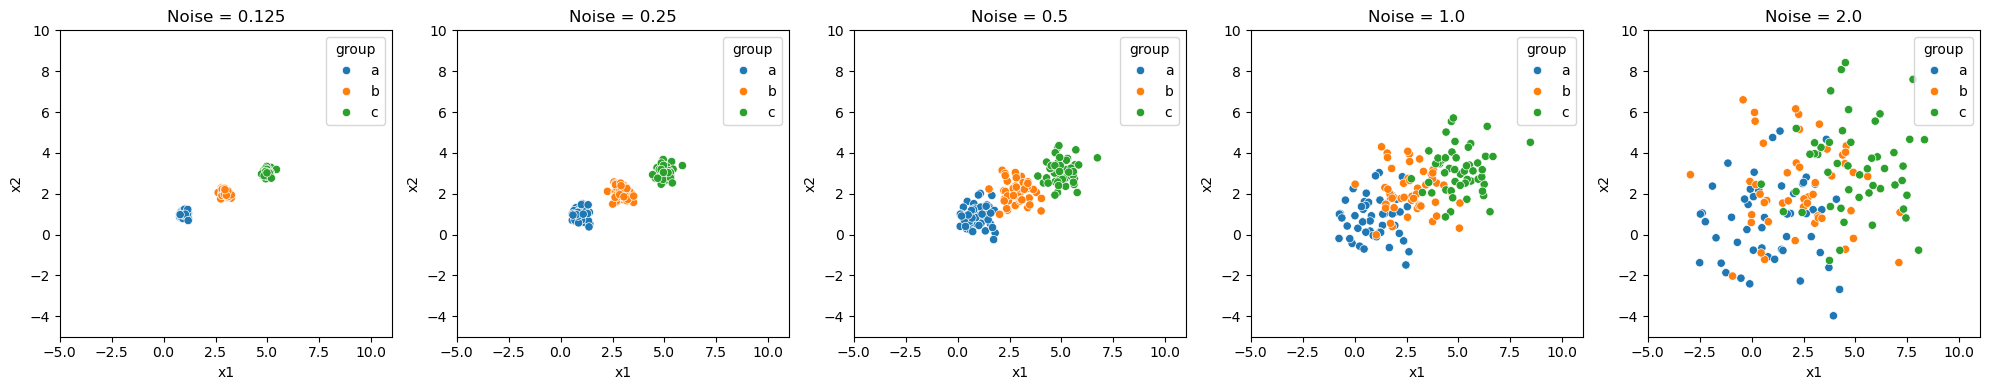

In [2]:

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, (noise, df) in zip(axes, datasets.items()):
    sns.scatterplot(
        data=df,
        x="x1",
        y="x2",
        hue="group",
        ax=ax
    )

    ax.set_title(f"Noise = {noise}")
    ax.set_xlim(-5, 11)
    ax.set_ylim(-5, 10)

plt.tight_layout()
plt.show()



As the noise increases, the three clusters become less visually distinct. At lower noise levels (0.125 and 0.25), the points are concentrated around their centers and are easy to distinguish. At 0.5, the groups begin to spread out but are still mostly separate. At higher noise levels (1.0 and 2.0), the points overlap much more, making it difficult to identify the original groups. This shows how increasing noise makes clustering more challenging.


Q1.3

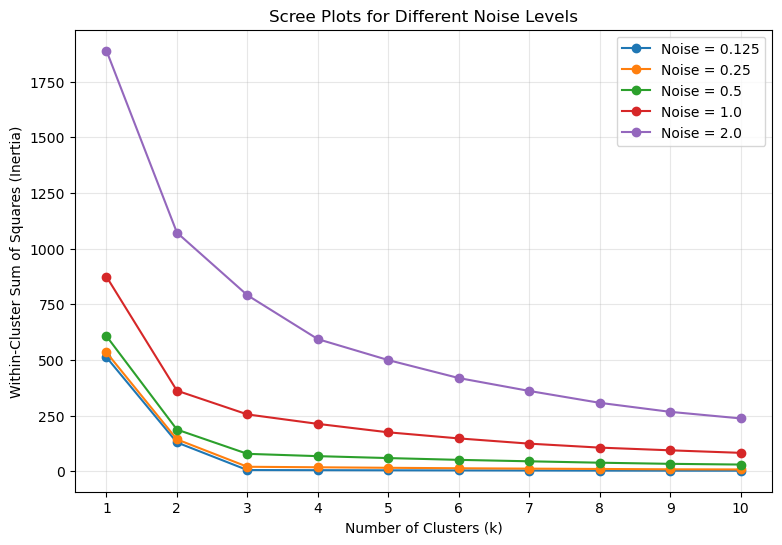

In [3]:

plt.figure(figsize=(9, 6))

for noise, df in datasets.items():
    X = df[["x1", "x2"]]
    inertia = []

    for k in range(1, 11):
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )
        model.fit(X)
        inertia.append(model.inertia_)

    plt.plot(
        range(1, 11),
        inertia,
        marker="o",
        label=f"Noise = {noise}"
    )

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.title("Scree Plots for Different Noise Levels")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


,Noise,Silhouette Score
0,0.125,0.896095
1,0.250,0.790426
2,0.500,0.580640
3,1.000,0.375077
4,2.000,0.360605


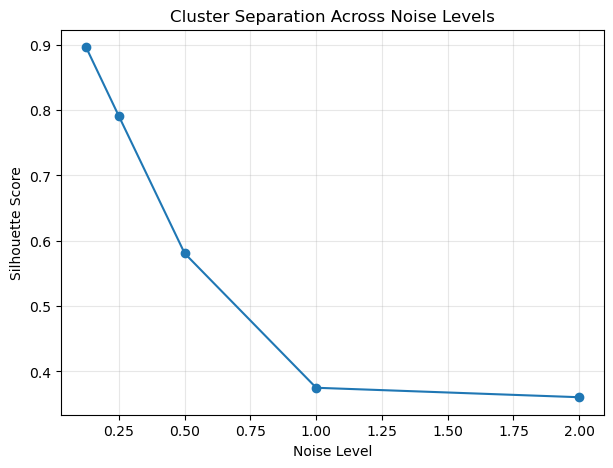

In [4]:

silhouette_results = []

for noise, df in datasets.items():
    X = df[["x1", "x2"]]

    model = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)
    score = silhouette_score(X, labels)

    silhouette_results.append({
        "Noise": noise,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df)

plt.figure(figsize=(7, 5))

plt.plot(
    silhouette_df["Noise"],
    silhouette_df["Silhouette Score"],
    marker="o"
)

plt.xlabel("Noise Level")
plt.ylabel("Silhouette Score")
plt.title("Cluster Separation Across Noise Levels")
plt.grid(alpha=0.3)
plt.show()



At lower noise levels, the scree plots show a clearer elbow around k = 3, which matches the three groups used to generate the data. As noise increases, the curves become smoother and the elbow becomes less obvious. This makes it harder to confidently select the correct number of clusters.

I also added silhouette scores to measure cluster separation. Higher silhouette scores indicate that clusters are more distinct, while lower scores indicate greater overlap. Comparing these scores across noise levels provides additional evidence of how increasing noise affects the clustering results. The inertia values also become larger as noise increases because the points are more spread out.


Q1.4


The elbow method helps determine a reasonable number of clusters by examining how inertia decreases as k increases. Adding more clusters reduces inertia, but eventually the improvements become smaller. The elbow is the point where the reduction begins to slow down.

In this simulation, k = 3 is a reasonable choice at lower noise levels because the data were generated from three distinct groups. Increasing k beyond 3 mostly divides the existing groups into smaller clusters rather than identifying meaningful new ones. At higher noise levels, the groups overlap more, making the elbow less clear. This shows that the elbow method is not always definitive and choosing k can become more subjective when the data contain substantial noise.


Q2.1

In [5]:

military = pd.read_csv(
    "./data/SIPRI Military Expenditure Database.csv"
)

features1 = [
    "Spending (2020 USD)",
    "Spending per Capita"
]

features2 = [
    "Percent of Government Spending",
    "Percent of GDP"
]

features3 = features1 + features2

military_2020 = military[military["Year"] == 2020].copy()

for col in features3:
    military_2020[col] = pd.to_numeric(
        military_2020[col],
        errors="coerce"
    )

military_2020 = military_2020.dropna(
    subset=features3
).copy()

print("Number of countries:", len(military_2020))

print("\nData types:")
print(military_2020[features3].dtypes)

print("\nMissing values:")
print(military_2020[features3].isna().sum())

print("\nDuplicate countries:")
print(military_2020["Country"].duplicated().sum())

display(military_2020.head())


Number of countries: 148

Data types:
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object

Missing values:
Spending (2020 USD)               0
Spending per Capita               0
Percent of Government Spending    0
Percent of GDP                    0
dtype: int64

Duplicate countries:
0


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731



After filtering the dataset to 2020 and removing observations with missing values in the four spending variables, I was left with 148 countries. All four variables were converted to numeric values. I also added checks for missing values and duplicate country entries to verify that the data were ready for clustering.

Since the spending variables are measured on different scales, I used min-max normalization before applying K-means. This places each variable on a scale from 0 to 1 so that variables with larger numerical values do not automatically dominate the clustering.


Q2.2

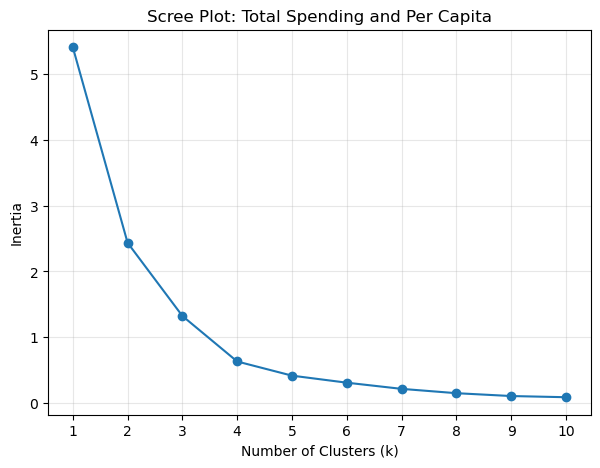

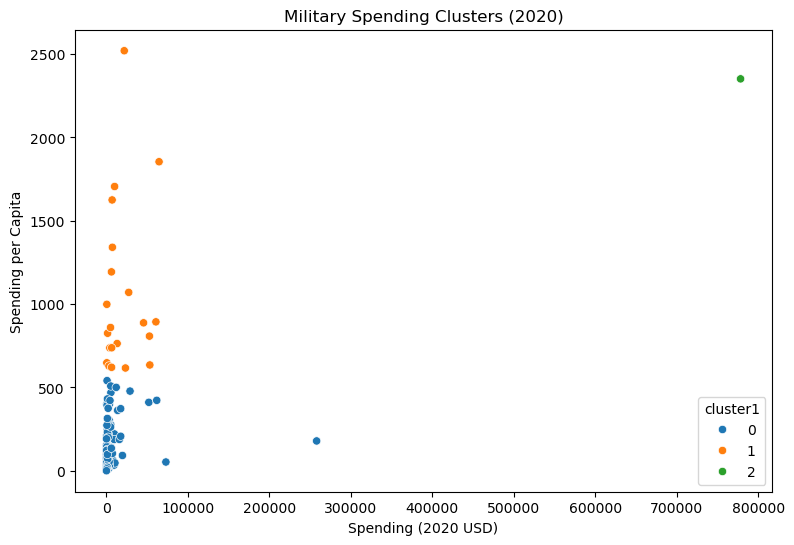

Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster1                                                                   
0                      126.0    5943.346303  24858.961064       8.622460   
1                       21.0   19975.991473  21749.736747     405.790494   
2                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster1                                                               
0            162.761743     580.758315    3225.333414  257973.429834   
1           4980.428135    7269.880030   27300.894701   64558.400000   
2         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita                                        \
                       count         mean         std          min   
cluster1                                                             
0                      126.0   122.034996  140.041183     0.580129   
1                       21.0  1046.433509  501.631845   616.854430   
2                        1.0  2351.631858         NaN  2351.631858   

                                                              
                  25%          50%          75%          max  
cluster1                                                      
0           18.505805    58.809109   188.249364   541.154778  
1          737.690186   859.880548  1193.598730  2520.398541  
2         2351.631858  2351.631858  2351.631858  2351.631858

,Countries,Mean_Total_Spending,Mean_Per_Capita
cluster1,,,
0,126,5943.35,122.03
1,21,19975.99,1046.43
2,1,778397.20,2351.63


Countries in each cluster:
cluster1
0    126
1     21
2      1
Name: count, dtype: int64

United States:


,Country,cluster1,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


In [6]:

scaler1 = MinMaxScaler()
X1 = scaler1.fit_transform(military_2020[features1])

inertia1 = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X1)
    inertia1.append(model.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertia1, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot: Total Spending and Per Capita")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.show()

model1 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

military_2020["cluster1"] = model1.fit_predict(X1)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=military_2020,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster1",
    palette="tab10"
)

plt.title("Military Spending Clusters (2020)")
plt.show()

display(
    military_2020.groupby("cluster1")[features1].describe()
)

summary1 = military_2020.groupby("cluster1").agg(
    Countries=("Country", "count"),
    Mean_Total_Spending=("Spending (2020 USD)", "mean"),
    Mean_Per_Capita=("Spending per Capita", "mean")
)

display(summary1.round(2))

print("Countries in each cluster:")
print(military_2020["cluster1"].value_counts().sort_index())

print("\nUnited States:")
display(
    military_2020.loc[
        military_2020["Country"] == "United States of America",
        ["Country", "cluster1"] + features1
    ]
)



I selected k = 3 based on the scree plot. The largest cluster contained 126 countries with relatively low total military spending and spending per capita. Another cluster contained 21 countries with higher average spending per capita. The United States formed its own cluster, with total military spending of approximately 778,397 in the dataset's units and spending per capita of approximately $2,352.

This suggests that the United States is an outlier in terms of total military spending. It also shows that countries can have relatively high spending per capita without having the largest total military budgets. One limitation is that the unusually high spending of the United States may influence the cluster boundaries, even after normalization.


Q2.3

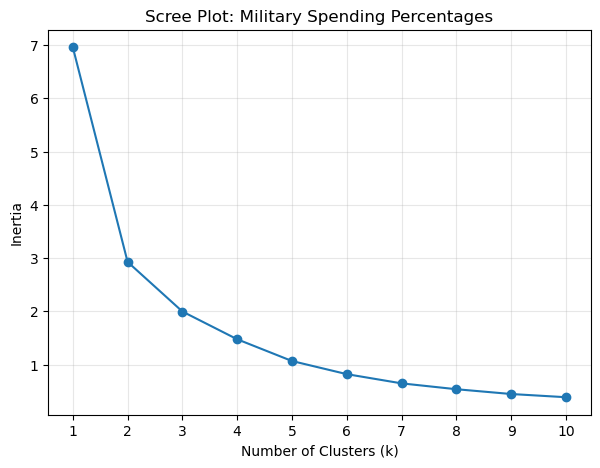

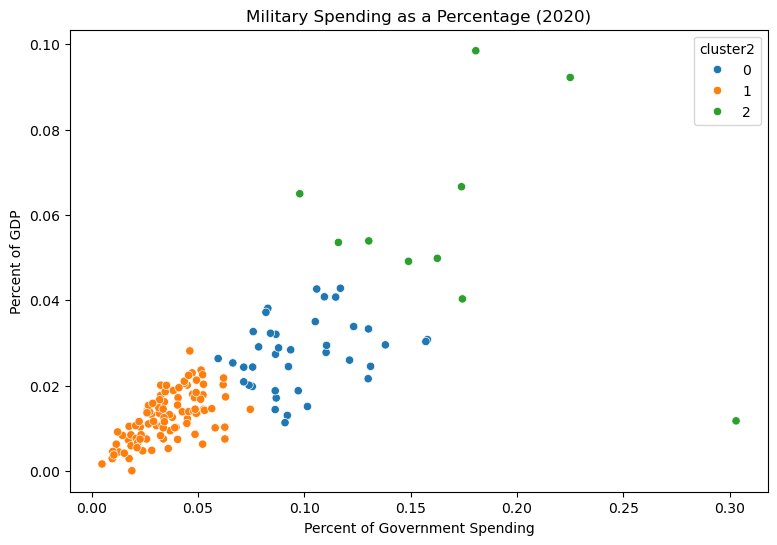

Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  99.0  0.035777  0.014549  0.004896   
2                                  10.0  0.171289  0.058725  0.097882   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                      
               std       min       25%       50%       75%       max  
cluster2                                                              
0         0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1         0.005681  0.000054  0.008393  0.013191  0.016752  0.028132  
2         0.024867  0.011742  0.049297  0.053729  0.066190  0.098470

,Countries,Mean_Government_Spending,Mean_GDP
cluster2,,,
0,39,0.0987,0.0274
1,99,0.0358,0.0127
2,10,0.1713,0.0581


Countries in each cluster:
cluster2
0    39
1    99
2    10
Name: count, dtype: int64

Countries in the highest GDP spending cluster:


,Country,Percent of Government Spending,Percent of GDP
4044,Oman,0.180654,0.098470
4486,Saudi Arabia,0.225050,0.092211
100,Algeria,0.173924,0.066600
2922,Kuwait,0.097882,0.064961
304,Azerbaijan,0.130339,0.053905
2582,Israel,0.116052,0.053553
202,Armenia,0.162572,0.049827
2718,Jordan,0.149025,0.049121
4078,Pakistan,0.174362,0.040317
406,Belarus,0.303027,0.011742


In [7]:

scaler2 = MinMaxScaler()
X2 = scaler2.fit_transform(military_2020[features2])

inertia2 = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X2)
    inertia2.append(model.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertia2, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot: Military Spending Percentages")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.show()

model2 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

military_2020["cluster2"] = model2.fit_predict(X2)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=military_2020,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster2",
    palette="tab10"
)

plt.title("Military Spending as a Percentage (2020)")
plt.show()

display(
    military_2020.groupby("cluster2")[features2].describe()
)

summary2 = military_2020.groupby("cluster2").agg(
    Countries=("Country", "count"),
    Mean_Government_Spending=(
        "Percent of Government Spending", "mean"
    ),
    Mean_GDP=("Percent of GDP", "mean")
)

display(summary2.round(4))

print("Countries in each cluster:")
print(military_2020["cluster2"].value_counts().sort_index())

cluster2_means = military_2020.groupby("cluster2")[
    "Percent of GDP"
].mean()

highest_cluster2 = cluster2_means.idxmax()

print("\nCountries in the highest GDP spending cluster:")

display(
    military_2020.loc[
        military_2020["cluster2"] == highest_cluster2,
        ["Country"] + features2
    ].sort_values("Percent of GDP", ascending=False)
)



I selected k = 3 for this analysis as well. The largest cluster contained 99 countries with relatively low military spending percentages. Another cluster contained 39 countries with moderate percentages, while the remaining 10 countries generally devoted higher percentages of their resources to the military. Countries in this last cluster included Oman, Saudi Arabia, and Israel.

Unlike the previous analysis, these clusters reflect how much of a country's GDP and government spending is allocated to the military rather than the total amount spent. For example, Oman and Saudi Arabia had relatively high military spending percentages even though their total military budgets were much smaller than that of the United States. This shows that total military spending and relative military spending can reveal different patterns.


Q2.4

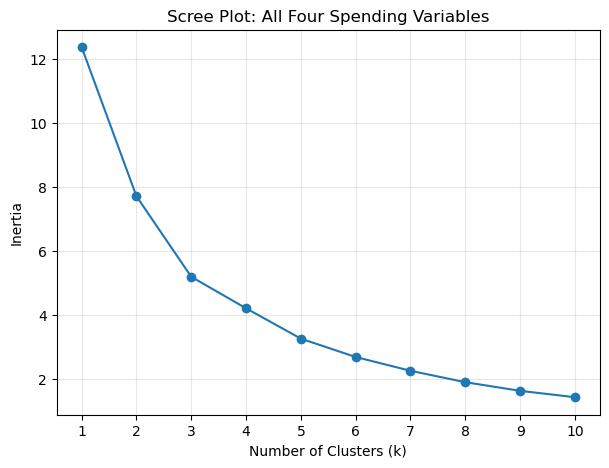

Countries in each cluster:
cluster3
0     31
1      6
2    111
Name: count, dtype: int64


Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster3                                                                  
0                       31.0    8786.086602   17901.909108   162.373364   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                      111.0    7086.472777   26479.379918     8.622460   

                                                                  \
                  25%           50%           75%            max   
cluster3                                                           
0          467.787851   1404.787234   7739.166193   72937.064048   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2          130.010211    567.650747   3910.107493  257973.429834   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...                            75%   
cluster3                                   ...                                  
0                       31.0   212.689100  ...                       0.134663   
1                        6.0  1875.150751  ...                       0.164503   
2                      111.0   196.926833  ...                       0.050505   

                   Percent of GDP                                          \
               max          count      mean       std       min       25%   
cluster3                                                                    
0         0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
1         0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2         0.092044          111.0  0.013419  0.005996  0.000054  0.008873   

                                        
               50%       75%       max  
cluster3                                
0         0.032024  0.040531  0.066600  
1         0.059257  0.085398  0.098470  
2         0.013589  0.017769  0.028132  

[3 rows x 32 columns]

,Countries,Mean_Total_Spending,Mean_Per_Capita,Mean_Government_Spending,Mean_GDP
cluster3,,,,,
0,31,8786.087,212.689,0.123,0.033
1,6,147964.582,1875.151,0.135,0.063
2,111,7086.473,196.927,0.040,0.013


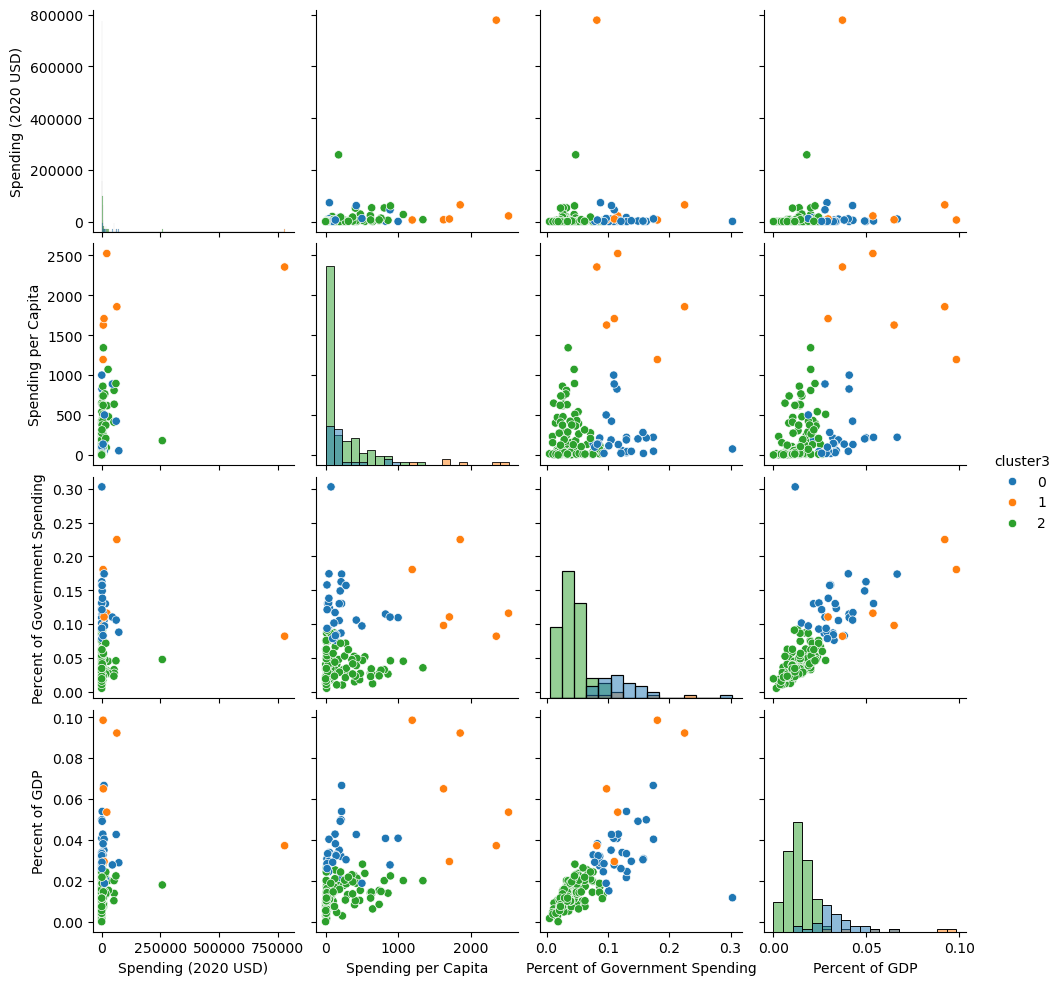

In [8]:

scaler3 = MinMaxScaler()
X3 = scaler3.fit_transform(military_2020[features3])

inertia3 = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X3)
    inertia3.append(model.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertia3, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot: All Four Spending Variables")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.show()

model3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

military_2020["cluster3"] = model3.fit_predict(X3)

print("Countries in each cluster:")
print(military_2020["cluster3"].value_counts().sort_index())

display(
    military_2020.groupby("cluster3")[features3].describe()
)

summary3 = military_2020.groupby("cluster3").agg(
    Countries=("Country", "count"),
    Mean_Total_Spending=("Spending (2020 USD)", "mean"),
    Mean_Per_Capita=("Spending per Capita", "mean"),
    Mean_Government_Spending=(
        "Percent of Government Spending", "mean"
    ),
    Mean_GDP=("Percent of GDP", "mean")
)

display(summary3.round(3))

sns.pairplot(
    military_2020,
    vars=features3,
    hue="cluster3",
    palette="tab10",
    diag_kind="hist"
)

plt.show()


In [9]:

print("Comparison of Q2.2 and Q2.4:")

display(
    pd.crosstab(
        military_2020["cluster1"],
        military_2020["cluster3"]
    )
)

print("Comparison of Q2.3 and Q2.4:")

display(
    pd.crosstab(
        military_2020["cluster2"],
        military_2020["cluster3"]
    )
)

us_cluster3 = military_2020.loc[
    military_2020["Country"] == "United States of America",
    "cluster3"
].iloc[0]

print("Countries in the same cluster as the United States:")

display(
    military_2020.loc[
        military_2020["cluster3"] == us_cluster3,
        ["Country"] + features3
    ]
)


Comparison of Q2.2 and Q2.4:


cluster3,0,1,2
cluster1,,,
0,28,0,98
1,3,5,13
2,0,1,0


Comparison of Q2.3 and Q2.4:


cluster3,0,1,2
cluster2,,,
0,25,2,12
1,0,0,99
2,6,4,0


Countries in the same cluster as the United States:


,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
2582,Israel,21816.569767,2520.398541,0.116052,0.053553
2922,Kuwait,6941.042345,1625.156250,0.097882,0.064961
4044,Oman,6095.708713,1193.598730,0.180654,0.098470
4486,Saudi Arabia,64558.400000,1854.380422,0.225050,0.092211
4656,Singapore,9978.571429,1705.738706,0.110489,0.029429
5540,United States of America,778397.200000,2351.631858,0.081976,0.037179



I selected k = 3 when using all four variables. The largest cluster contained 111 countries, while the other two clusters contained 31 and 6 countries. The six-country cluster included the United States, Israel, Kuwait, Oman, Saudi Arabia, and Singapore.

One major difference was that the United States no longer formed its own cluster. Instead, it was grouped with countries that had relatively high military spending per capita or devoted larger percentages of their resources to the military. This suggests that including additional variables changes how the algorithm measures similarity between countries.

The crosstabs also showed that several countries were reassigned when different combinations of variables were used. Although all three models used k = 3, they produced different groupings because they emphasized different aspects of military spending.


Q2.5


I think K-means clustering was useful for identifying general patterns in military spending. One thing I noticed was that countries with the largest military budgets were not necessarily the countries devoting the largest percentages of their resources to the military. This became clearer when comparing the three clustering models.

I also found it interesting that the United States formed its own cluster when using total spending and spending per capita, but was grouped with five other countries when all four variables were included. This shows how the variables selected for clustering can affect the results.

However, K-means has some limitations. It is sensitive to outliers, and min-max normalization can be influenced by extreme values. The choice of k can also be subjective when the scree plot does not show a clear elbow. Overall, I think clustering was helpful for comparing spending patterns across countries, but it does not explain why individual countries spend the amounts they do.


### *Reflection on AI assistance
In your own words without generative AI.

Using AI for Phase 2 helped me improve my original work by identifying areas where I could make my analysis more thorough. Most of my code from Phase 1 was already working correctly, so I mainly used AI to check my interpretations and suggest additional ways to evaluate the results. One useful suggestion was adding silhouette scores to Q1, which gave me another way to assess how increasing noise affected cluster separation beyond just looking at the scatterplots and scree plots. For Q2, it suggested adding summary tables with cluster sizes and mean spending values. I thought this was helpful because my original describe tables contained a lot of information and were harder to interpret. It also helped me expand my explanations of why the United States formed its own cluster in one model but was grouped with other countries when all four variables were included.

However, not all of the suggestions were necessary. Some of the proposed changes, such as checking data types and comparing cluster membership, were things I had already done in Phase 1. I modified these suggestions rather than repeating the same work. I also recognized that AI could not directly verify my results without running the code on my dataset, so I needed to check the outputs myself. Overall, I found AI most useful for reviewing my work and improving my explanations rather than generating an entirely new solution. I still think the choice of k and the influence of outliers are important limitations to consider.